<a href="https://colab.research.google.com/github/Pedro-Veiga0/ESP32-AC-Telegram-Controller/blob/main/HyperparameterOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install Anomalib with full dependencies
!pip install --quiet "anomalib[full]"

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 859.9/859.9 kB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 149.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 128.3 MB/s eta 0:00:00
 

In [ ]:
!pip install --quiet optuna openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 6.6 MB/s eta 0:00:00


# Blocks

In [ ]:
import gc
import os
import torch
import optuna
import datetime
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

# Ensure PyTorch operations are optimized
torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive Safely and Configure Dataset Paths
drive.mount('/content/drive', force_remount=False)

drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_hyp_optim_vit_small_num_blocks.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# We will loop through each class individually
for category in TEXTURE_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} ================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=2,
    )

    def objective(trial):
        # Clean GPU memory before trial runs
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter Space: Single block from blocks.0 to blocks.11
        selected_block = trial.suggest_categorical(
            "selected_block",
            [f"blocks.{i}" for i in range(12)]
        )
        layers = [selected_block]

        # Fixed Configuration
        backbone = "vit_small_patch16_dinov3"
        coreset_ratio = 0.1
        knn_neighbors = 9

        # Custom Evaluator with requested metrics
        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model & Engine Setup
        model = Patchcore(
            backbone=backbone,
            layers=layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        engine = Engine(
            default_root_dir=f"./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        # 4. Training and Evaluation
        try:
            start_time = datetime.datetime.now()
            engine.fit(datamodule=datamodule, model=model)
            test_results = engine.test(datamodule=datamodule, model=model)[0]
            end_time = datetime.datetime.now()
            training_duration = (end_time - start_time).total_seconds() / 60 # in minutes

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)

            # Estimate disk size of the memory bank
            memory_bank_size_mb = estimate_memory_bank_size(model)

            # Log values inside trial attributes for tracking
            trial.set_user_attr("AUPIMO", aupimo)
            trial.set_user_attr("Image_AUROC", image_auroc)
            trial.set_user_attr("Memory_Bank_MB", memory_bank_size_mb)

            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Layers_Used": selected_block,
                "Coreset_Ratio": coreset_ratio,
                "KNN": knn_neighbors,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Training_Duration_Minutes": round(float(training_duration), 2)
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df

            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Block: {selected_block} | AUPRO: {aupro:.4f} | AUPIMO: {aupimo:.4f} | Size: {memory_bank_size_mb:.2f} MB | Train Time: {training_duration:.2f} min")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to error: {e}")
            return 0.0

    # 5. Initialize Optuna Study with 6 random startup trials (since we do 10 total trials per class)
    sampler = optuna.samplers.TPESampler(n_startup_trials=6, seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)

    # Run optimization for 10 total trials for the current class
    print(f"Starting 10 Optuna Optimization trials for {category}...")
    study.optimize(objective, n_trials=10)

    # 6. Display Best Results for current class
    print(f"\n========== OPTIMIZATION COMPLETED FOR {category.upper()} ==========")
    print(f"Best Trial Number: {study.best_trial.number}")
    print(f"Best Target (AUPRO): {study.best_value:.4f}")
    print(f"Best Parameters: {study.best_params}")
    print(f"Best Trial AUPIMO: {study.best_trial.user_attrs.get('AUPIMO', 0.0):.4f}")
    print(f"Best Trial Memory Bank Size: {study.best_trial.user_attrs.get('Memory_Bank_MB', 0.0):.2f} MB")
    print(f"Best Trial Training Duration: {study.best_trial.user_attrs.get('Training_Duration_Minutes', 0.0):.2f} minutes\n")


[I 2026-09-22 16:16:09,560] A new study created in memory with name: no-name-aa7c7a06-9828-4b3c-b61a-a21fce439f76


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

================ STARTING OPTIMIZATION FOR CLASS: GRID ================
Starting 10 Optuna Optimization trials for grid...


INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 21.6 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 253 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 6322/6322 [00:10<00:00, 611.23it/s] 
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.1399291596175792     │
│           AUPRO           │    0.7282969951629639     │
│        image_AUROC        │    0.8464912176132202     │
│        pixel_AUROC        │    0.9205074310302734     │
└───────────────────────────┴───────────────────────────┘

[I 2026-09-22 16:56:16,233] Trial 9 finished with value: 0.7282969951629639 and parameters: {'selected_block': 'blocks.8'}. Best is trial 5 with value: 0.7679231762886047.


[WOOD] Trial 9 finished. Block: blocks.8 | AUPRO: 0.7283 | AUPIMO: 0.1399 | Size: 9.26 MB | Train Time: 0.93 min

========== OPTIMIZATION COMPLETED FOR WOOD ==========
Best Trial Number: 5
Best Target (AUPRO): 0.7679
Best Parameters: {'selected_block': 'blocks.9'}
Best Trial AUPIMO: 0.1217
Best Trial Memory Bank Size: 9.26 MB
Best Trial Training Duration: 0.00 minutes



# Feature Pooler

In [ ]:
import gc
import os
import torch
import optuna
import datetime
import time
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive and set up logging
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_pooler_optimization_vit_small.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# We will loop through each class individually
for category in ALL_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} =================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    def objective(trial):
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter space for Feature Pooler
        pool_size = trial.suggest_categorical("pool_size", [1, 3, 5])

        # Other model configuration defaults matching your setup
        backbone = "vit_small_patch16_dinov3"
        layers = ["blocks.7"]
        coreset_ratio = 0.1
        knn_neighbors = 9

        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model instantiation
        model = Patchcore(
            backbone=backbone,
            layers=layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        # 4. Modify the feature_pooler within model.model
        if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
            padding = pool_size // 2
            model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
            print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride={1}, padding={padding})")
        else:
            print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

        # 5. Engine setup and run
        engine = Engine(
            default_root_dir="./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        try:
            start_fit = time.perf_counter()
            engine.fit(datamodule=datamodule, model=model)
            fit_duration_min = round((time.perf_counter() - start_fit) / 60.0, 3)

            test_results = engine.test(datamodule=datamodule, model=model)[0]

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)

            # Estimate disk size of the memory bank
            memory_bank_size_mb = estimate_memory_bank_size(model)

            # 6. Log configuration and scores
            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Pool_Size": pool_size,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Fit_Time_Min": fit_duration_min
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df
            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Pool Size: {pool_size} | AUPRO: {aupro:.4f} | Size: {memory_bank_size_mb:.2f} MB")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to: {e}")
            return 0.0

    # 7. Start the study for current class
    sampler = optuna.samplers.TPESampler(n_startup_trials=6, seed=42)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=6)

    print(f"\n========== OPTIMIZATION COMPLETED FOR {category.upper()} ==========")
    print(f"Best Pool Size: {study.best_params}")
    print(f"Best AUPRO Score: {study.best_value:.4f}\n")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
[I 2026-09-23 13:01:48,972] A new study created in memory with name: no-name-9b3fc66d-61c5-4e0f-9474-4cee3ab4d4b3


Mounted at /content/drive

================ STARTING OPTIMIZATION FOR CLASS: BOTTLE =================


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.1356980876255062     │
│           AUPRO           │    0.4313516318798065     │
│        image_AUROC        │     0.719298243522644     │
│        pixel_AUROC        │    0.8632781505584717     │
└───────────────────────────┴───────────────────────────┘

[I 2026-09-23 14:49:04,371] Trial 5 finished with value: 0.4313516318798065 and parameters: {'pool_size': 5}. Best is trial 4 with value: 0.9144464731216431.


[WOOD] Trial 5 finished. Pool Size: 5 | AUPRO: 0.4314 | Size: 9.26 MB

========== OPTIMIZATION COMPLETED FOR WOOD ==========
Best Pool Size: {'pool_size': 1}
Best AUPRO Score: 0.9144



# Dynamic Optimization

In [ ]:
import gc
import os
import torch
import optuna
import datetime
import time
import pandas as pd
from pathlib import Path
from google.colab import drive
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

# 1. Mount Google Drive and set up logging
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_multidim_optim_vit_small.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# Define the full 15 classes from MVTec AD
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size()
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

# Loop through each category to perform optimization
for category in ALL_CATEGORIES:
    print(f"\n================ STARTING OPTIMIZATION FOR CLASS: {category.upper()} =================")

    # Setup datamodule for the current category
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    def objective(trial):
        # Clear GPU Memory
        gc.collect()
        torch.cuda.empty_cache()

        # 2. Hyperparameter Space: Pool Size & Layers
        pool_size = trial.suggest_categorical("pool_size", [1, 3, 5])
        num_layers = trial.suggest_int("num_layers", 1, 3)

        # Dynamically select 'num_layers' unique block indices from blocks.0 to blocks.11
        available_blocks = [f"blocks.{i}" for i in range(12)]
        chosen_layers = []
        for i in range(num_layers):
            layer = trial.suggest_categorical(f"layer_selection_{i}", available_blocks)
            chosen_layers.append(layer)

        # Ensure unique block selection
        chosen_layers = list(sorted(list(set(chosen_layers))))

        # Base configuration
        backbone = "vit_small_patch16_dinov3"
        coreset_ratio = 0.1
        knn_neighbors = 9

        metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]
        evaluator = Evaluator(test_metrics=metrics)

        # 3. Model instantiation
        model = Patchcore(
            backbone=backbone,
            layers=chosen_layers,
            coreset_sampling_ratio=coreset_ratio,
            num_neighbors=knn_neighbors,
            evaluator=evaluator
        )

        # 4. Modify the feature_pooler (retains AvgPool2d only)
        if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
            padding = pool_size // 2
            model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
            print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
        else:
            print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

        # 5. Engine Setup and Fit
        engine = Engine(
            default_root_dir="./results",
            accelerator="gpu",
            devices=1,
            enable_progress_bar=False,
        )

        try:
            start_fit = time.perf_counter()
            engine.fit(datamodule=datamodule, model=model)
            fit_duration_min = round((time.perf_counter() - start_fit) / 60.0, 3)

            test_results = engine.test(datamodule=datamodule, model=model)[0]

            aupro = test_results.get("AUPRO", 0.0)
            aupimo = test_results.get("AUPIMO", 0.0)
            image_auroc = test_results.get("image_AUROC", 0.0)
            pixel_auroc = test_results.get("pixel_AUROC", 0.0)

            memory_bank_size_mb = estimate_memory_bank_size(model)

            # Log results inside trial attributes
            trial.set_user_attr("AUPIMO", aupimo)
            trial.set_user_attr("Image_AUROC", image_auroc)
            trial.set_user_attr("Pixel_AUROC", pixel_auroc)
            trial.set_user_attr("Memory_Bank_MB", memory_bank_size_mb)
            trial.set_user_attr("Fit_Time_Min", fit_duration_min)

            # 6. Save back to Persistent Excel Spreadsheet
            new_record = {
                "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "Class": category,
                "Trial_Number": trial.number,
                "Backbone": backbone,
                "Layers_Used": ", ".join(chosen_layers),
                "Pool_Size": pool_size,
                "AUPRO": round(float(aupro), 4),
                "AUPIMO": round(float(aupimo), 4),
                "Image_AUROC": round(float(image_auroc), 4),
                "Pixel_AUROC": round(float(pixel_auroc), 4),
                "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
                "Fit_Time_Min": fit_duration_min
            }

            new_df = pd.DataFrame([new_record])
            if excel_log_path.exists():
                existing_df = pd.read_excel(excel_log_path)
                updated_df = pd.concat([existing_df, new_df], ignore_index=True)
            else:
                updated_df = new_df
            updated_df.to_excel(excel_log_path, index=False)

            print(f"[{category.upper()}] Trial {trial.number} finished. Layers: {chosen_layers} | Pool Size: {pool_size} | AUPRO: {aupro:.4f} | Size: {memory_bank_size_mb:.2f} MB")
            return aupro

        except Exception as e:
            print(f"[{category.upper()}] Trial {trial.number} failed due to: {e}")
            return 0.0

    # 7. Setup Optuna Study for current class
    sampler = optuna.samplers.TPESampler(n_startup_trials=20, seed=42, multivariate=True, gamma=0.15)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=15)

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


/tmp/ipykernel_841/880540774.py:163: FutureWarning: `gamma` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  sampler = optuna.samplers.TPESampler(n_startup_trials=20, seed=42, multivariate=True, gamma=0.15)
[I 2026-09-24 12:23:23,133] A new study created in memory with name: no-name-a137912d-3d0b-4705-a127-78bf62f3d6a0



================ STARTING OPTIMIZATION FOR CLASS: BOTTLE =================


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.5663460992645176     │
│           AUPRO           │    0.7256677746772766     │
│        image_AUROC        │     0.986842155456543     │
│        pixel_AUROC        │    0.9030556082725525     │
└───────────────────────────┴───────────────────────────┘

[I 2026-09-24 16:41:31,339] Trial 14 finished with value: 0.7256677746772766 and parameters: {'pool_size': 1, 'num_layers': 1, 'layer_selection_0': 'blocks.11'}. Best is trial 9 with value: 0.9319254159927368.


[WOOD] Trial 14 finished. Layers: ['blocks.11'] | Pool Size: 1 | AUPRO: 0.7257 | Size: 9.26 MB


# Grid Search

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = 0.10
KNN_NEIGHBORS = 9
pool_size = 1

# User specified combinations of layers
layer_experiments = [
    ["blocks.1", "blocks.10", "blocks.8"],
    ["blocks.3", "blocks.5"],
    ["blocks.1", "blocks.10"],
    ["blocks.0", "blocks.11", "blocks.8"],
    ["blocks.1", "blocks.10", "blocks.5"]
]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for layers in layer_experiments:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
        ]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # Modify the feature pooler as requested
    if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
        padding = pool_size // 2
        model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
        print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
    else:
        print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with layers {layers} and pool_size {pool_size}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", 0.0)
    pixel_auroc = test_results.get("pixel_AUROC", 0.0)
    aupro = test_results.get("AUPRO", 0.0)
    aupimo = test_results.get("AUPIMO", 0.0)
    memory_bank_size_mb = estimate_memory_bank_size(model)

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "AUPRO": round(float(aupro), 4),
        "AUPIMO": round(float(aupimo), 4),
        "Memory_Bank_MB": round(float(memory_bank_size_mb), 2)
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

    # Display current logged history
    print("\n========== EXPERIMENT LOG HISTORY ==========")
    print(updated_df.to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.
INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Successfully updated feature_pooler: AvgPool2d(kernel_size=1, stride=1, padding=0)

Fitting PatchCore (vit_small_patch16_dinov3) on cable with layers ['blocks.0'] and pool_size 1...


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 21.6 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

Training completed in: 31.84s (0.53 min)
Running test evaluation...


ValueError: Invalid `fpr_level` because it's out of the range of `shared_fpr` = [0.0018376317517510776, 1.0], and got 1e-05.

# Data Visualization

Mounted at /content/drive


/tmp/ipykernel_1784/2726674644.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(grouped["Layers_Used"], rotation=30, ha="right")
/tmp/ipykernel_1784/2726674644.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(grouped["Layers_Used"], rotation=30, ha="right")
/tmp/ipykernel_1784/2726674644.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(grouped["Layers_Used"], rotation=30, ha="right")


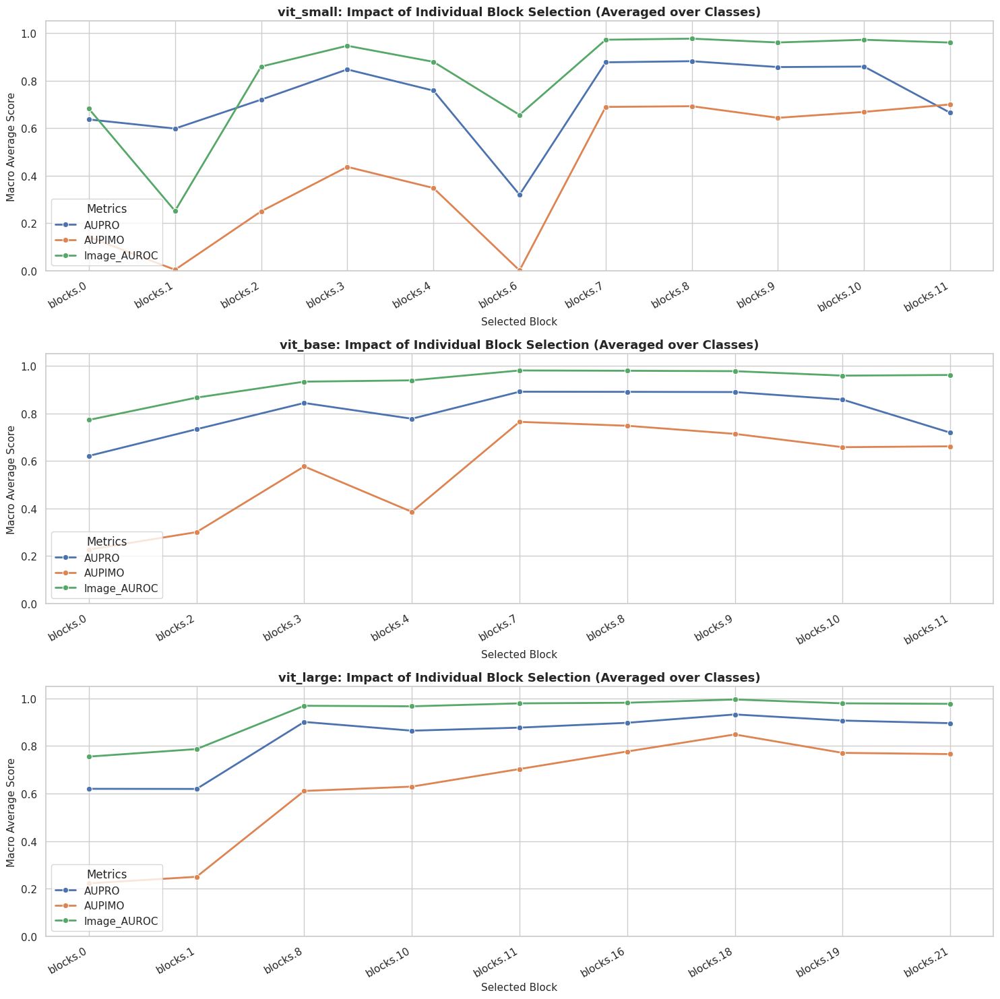

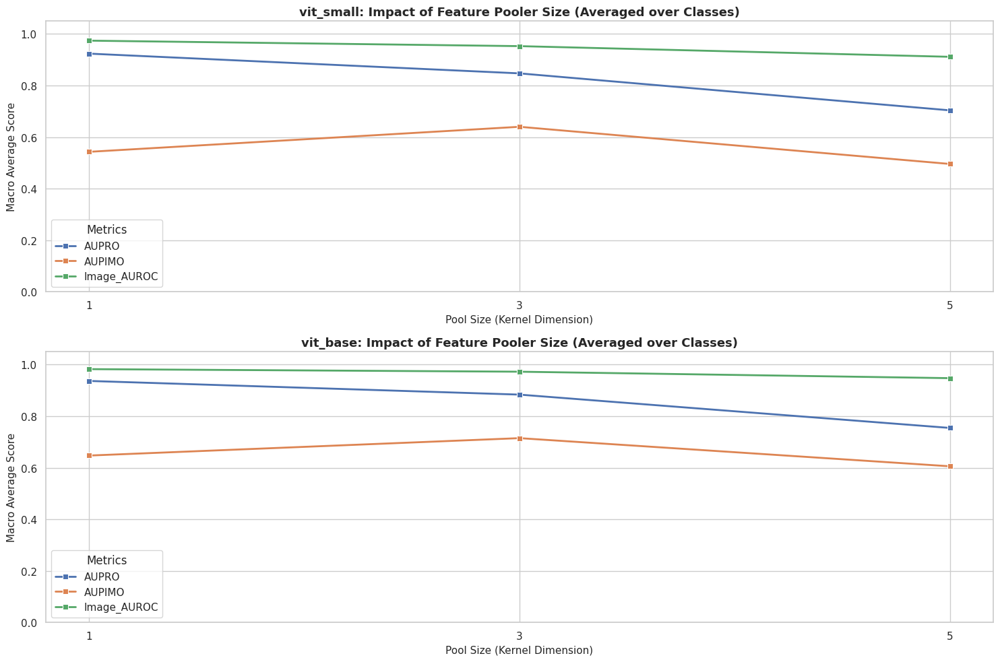

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=False)

sns.set_theme(style="whitegrid")

# 2. Define File Paths
blocks_paths = {
    "vit_small": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_hyp_optim_vit_small_num_blocks.xlsx"),
    "vit_base": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_hyp_optim_vit_base_num_blocks.xlsx"),
    "vit_large": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_hyp_optim_vit_large_num_blocks.xlsx")
}

pooler_paths = {
    "vit_small": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_pooler_optimization_vit_small.xlsx"),
    "vit_base": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_pooler_optimization_vit_base.xlsx")
}

# 3. Load and Visualize Number of Blocks Optimization
blocks_dfs = {}
for name, path in blocks_paths.items():
    if path.exists():
        df = pd.read_excel(path)
        # Ensure we can order layers correctly
        if "Layers_Used" in df.columns:
            df["Block_Index"] = df["Layers_Used"].str.extract(r'(\d+)').astype(float)
            blocks_dfs[name] = df

if blocks_dfs:
    fig, axes = plt.subplots(len(blocks_dfs), 1, figsize=(15, 5 * len(blocks_dfs)))
    if len(blocks_dfs) == 1:
        axes = [axes]

    for idx, (name, df) in enumerate(blocks_dfs.items()):
        ax = axes[idx]
        # Calculate mean scores grouped by layer block selection
        grouped = df.groupby("Layers_Used")[["AUPRO", "AUPIMO", "Image_AUROC"]].mean().reset_index()
        grouped["Block_Index"] = grouped["Layers_Used"].str.extract(r'(\d+)').astype(int)
        grouped = grouped.sort_values("Block_Index")

        melted = grouped.melt(id_vars=["Layers_Used"], value_vars=["AUPRO", "AUPIMO", "Image_AUROC"], var_name="Metric", value_name="Score")

        sns.lineplot(data=melted, x="Layers_Used", y="Score", hue="Metric", marker="o", linewidth=2, ax=ax)
        ax.set_title(f"{name}: Impact of Individual Block Selection (Averaged over Classes)", fontsize=13, fontweight="bold")
        ax.set_xlabel("Selected Block", fontsize=11)
        ax.set_ylabel("Macro Average Score", fontsize=11)
        ax.set_ylim(0.0, 1.05)
        ax.set_xticklabels(grouped["Layers_Used"], rotation=30, ha="right")
        ax.legend(title="Metrics", loc="lower left")

    plt.tight_layout()
    plt.show()
else:
    print("No blocks optimization logs found to visualize.")

# 4. Load and Visualize Feature Pooler Size Optimization
pooler_dfs = {}
for name, path in pooler_paths.items():
    if path.exists():
        df = pd.read_excel(path)
        pooler_dfs[name] = df

if pooler_dfs:
    fig, axes = plt.subplots(len(pooler_dfs), 1, figsize=(15, 5 * len(pooler_dfs)))
    if len(pooler_dfs) == 1:
        axes = [axes]

    for idx, (name, df) in enumerate(pooler_dfs.items()):
        ax = axes[idx]
        # Calculate mean scores grouped by pooler size
        grouped = df.groupby("Pool_Size")[["AUPRO", "AUPIMO", "Image_AUROC"]].mean().reset_index()
        melted = grouped.melt(id_vars=["Pool_Size"], value_vars=["AUPRO", "AUPIMO", "Image_AUROC"], var_name="Metric", value_name="Score")

        sns.lineplot(data=melted, x="Pool_Size", y="Score", hue="Metric", marker="s", linewidth=2, ax=ax)
        ax.set_title(f"{name}: Impact of Feature Pooler Size (Averaged over Classes)", fontsize=13, fontweight="bold")
        ax.set_xlabel("Pool Size (Kernel Dimension)", fontsize=11)
        ax.set_ylabel("Macro Average Score", fontsize=11)
        ax.set_xticks([1, 3, 5])
        ax.set_ylim(0.0, 1.05)
        ax.legend(title="Metrics", loc="lower left")

    plt.tight_layout()
    plt.show()
else:
    print("No pooler optimization logs found to visualize.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully loaded vit_small log with 224 rows.
Successfully loaded vit_base log with 225 rows.
Successfully loaded vit_large log with 225 rows.


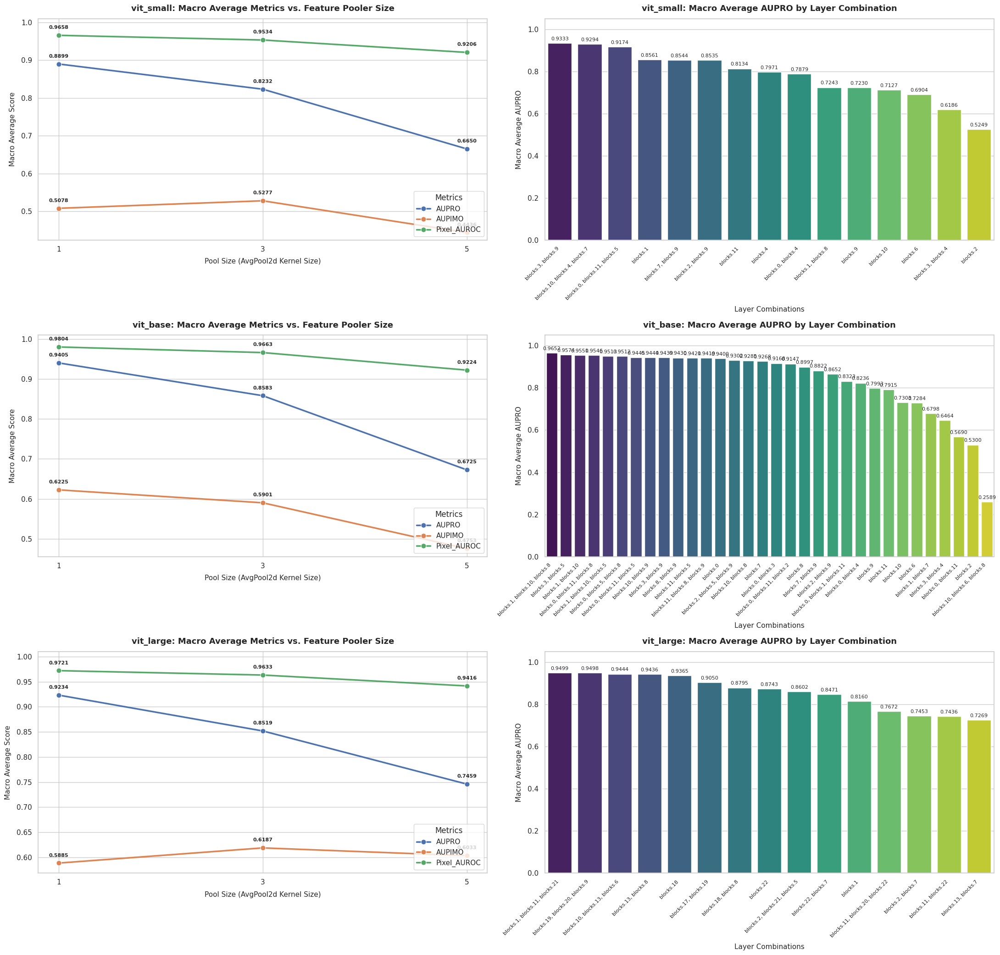

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Ensure Google Drive is mounted
drive.mount('/content/drive', force_remount=False)

# 2. Paths to all multidimensional optimization logs
log_paths = {
    "vit_small": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_multidim_optim_vit_small.xlsx"),
    "vit_base": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_multidim_optim_vit_base.xlsx"),
    "vit_large": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_multidim_optim_vit_large.xlsx")
}

# Load and label datasets
dfs = {}
for name, path in log_paths.items():
    if path.exists():
        df = pd.read_excel(path)
        # Standardize Layer Names
        def clean_layers(layer_str):
            if not isinstance(layer_str, str):
                return ""
            return ", ".join([p.strip() for p in layer_str.split(",")])
        df["Clean_Layers"] = df["Layers_Used"].apply(clean_layers)
        dfs[name] = df
        print(f"Successfully loaded {name} log with {len(df)} rows.")
    else:
        print(f"Warning: The file for {name} at {path} was not found.")

if dfs:
    # Set up matplotlib figure to draw comparison charts
    # We create a grid: 3 rows (one per backbone), 2 columns (Left: Pool Size line chart, Right: Layer bar chart)
    fig, axes = plt.subplots(len(dfs), 2, figsize=(22, 7 * len(dfs)))
    sns.set_theme(style="whitegrid")

    # Handle 1D array of axes if only one dataframe was loaded
    if len(dfs) == 1:
        axes = axes.reshape(1, 2)

    for idx, (name, df) in enumerate(dfs.items()):
        ax_line = axes[idx, 0]
        ax_bar = axes[idx, 1]

        # --- Plot 1: Line Chart of Metrics vs. Pool Size ---
        macro_averages = df.groupby("Pool_Size")[["AUPRO", "AUPIMO", "Pixel_AUROC"]].mean().reset_index()
        melted_averages = macro_averages.melt(
            id_vars=["Pool_Size"],
            value_vars=["AUPRO", "AUPIMO", "Pixel_AUROC"],
            var_name="Metric",
            value_name="Macro_Average_Score"
        )

        sns.lineplot(
            data=melted_averages,
            x="Pool_Size",
            y="Macro_Average_Score",
            hue="Metric",
            marker="o",
            linewidth=2.5,
            markersize=8,
            ax=ax_line
        )
        ax_line.set_title(f"{name}: Macro Average Metrics vs. Feature Pooler Size", fontsize=13, fontweight="bold", pad=12)
        ax_line.set_xlabel("Pool Size (AvgPool2d Kernel Size)", fontsize=11, labelpad=8)
        ax_line.set_ylabel("Macro Average Score", fontsize=11, labelpad=8)
        ax_line.set_xticks([1, 3, 5])
        ax_line.set_ylim(min(melted_averages["Macro_Average_Score"].min() - 0.02, 0.8), 1.01)
        ax_line.legend(title="Metrics", loc="lower right")

        # Annotate values on the line plot points
        for line in ax_line.lines:
            x_data = line.get_xdata()
            y_data = line.get_ydata()
            for x, y in zip(x_data, y_data):
                if pd.notna(y):
                    ax_line.annotate(f"{y:.4f}",
                                 (x, y),
                                 textcoords="offset points",
                                 xytext=(0,10),
                                 ha='center',
                                 fontsize=8,
                                 fontweight='semibold')

        # --- Plot 2: Bar Chart of AUPRO by Layer Combination ---
        layer_aupro_averages = df.groupby("Clean_Layers")["AUPRO"].mean().reset_index().sort_values(by="AUPRO", ascending=False)

        sns.barplot(
            data=layer_aupro_averages,
            x="Clean_Layers",
            y="AUPRO",
            hue="Clean_Layers",
            palette="viridis",
            legend=False,
            ax=ax_bar
        )
        ax_bar.set_title(f"{name}: Macro Average AUPRO by Layer Combination", fontsize=13, fontweight="bold", pad=12)
        ax_bar.set_xlabel("Layer Combinations", fontsize=11, labelpad=8)
        ax_bar.set_ylabel("Macro Average AUPRO", fontsize=11, labelpad=8)

        # Set x-ticks and rotation properly
        ax_bar.set_xticks(range(len(layer_aupro_averages)))
        ax_bar.set_xticklabels(layer_aupro_averages["Clean_Layers"], rotation=45, ha="right", fontsize=8)
        ax_bar.set_ylim(0.0, 1.05)

        # Annotate values on the bar chart bars
        for p in ax_bar.patches:
            height = p.get_height()
            if height > 0:
                ax_bar.annotate(f'{height:.4f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=8, xytext=(0, 3),
                            textcoords='offset points')

    plt.tight_layout()
    plt.show()
else:
    print("Error: No log files were loaded. Please check that files exist in the specified Google Drive paths.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully loaded vit_small grid search log with 45 rows.
Successfully loaded vit_base grid search log with 75 rows.
Successfully loaded vit_large grid search log with 60 rows.


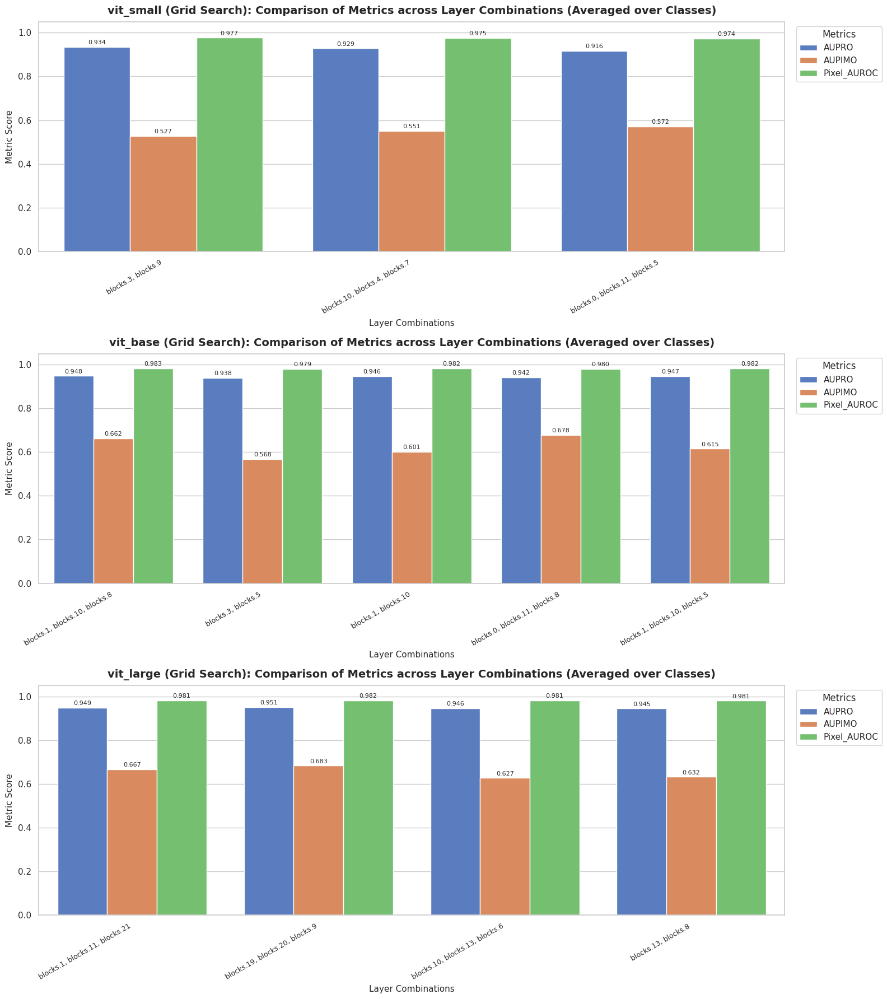

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Ensure Google Drive is mounted
drive.mount('/content/drive', force_remount=False)

# 2. Paths to grid search logs (the selected combinations)
log_paths = {
    "vit_small": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_small.xlsx"),
    "vit_base": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base.xlsx"),
    "vit_large": Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_large.xlsx")
}

# Load and clean datasets
dfs = {}
for name, path in log_paths.items():
    if path.exists():
        df = pd.read_excel(path)
        # Standardize Layer Names to ease matching
        def clean_layers(layer_str):
            if not isinstance(layer_str, str):
                return ""
            return ", ".join([p.strip() for p in layer_str.split(",")])
        df["Clean_Layers"] = df["Layers_Used"].apply(clean_layers)
        dfs[name] = df
        print(f"Successfully loaded {name} grid search log with {len(df)} rows.")
    else:
        print(f"Warning: The file for {name} at {path} was not found.")

if dfs:
    sns.set_theme(style="whitegrid")
    # Setup a grid of subplots: one row per backbone
    fig, axes = plt.subplots(len(dfs), 1, figsize=(16, 6 * len(dfs)))

    # Ensure axes is iterable even if only one dataset is loaded
    if len(dfs) == 1:
        axes = [axes]

    for idx, (name, df) in enumerate(dfs.items()):
        ax = axes[idx]

        # Melt the DataFrame to long format for easier grouped visualization
        melted_df = df.melt(
            id_vars=["Clean_Layers"],
            value_vars=["AUPRO", "AUPIMO", "Pixel_AUROC"],
            var_name="Metric",
            value_name="Score"
        )

        # Plot grouped bar chart for current backbone
        sns.barplot(
            data=melted_df,
            x="Clean_Layers",
            y="Score",
            hue="Metric",
            errorbar=None,  # Average across classes
            palette="muted",
            ax=ax
        )

        ax.set_title(f"{name} (Grid Search): Comparison of Metrics across Layer Combinations (Averaged over Classes)", fontsize=14, fontweight="bold", pad=10)
        ax.set_xlabel("Layer Combinations", fontsize=11, labelpad=5)
        ax.set_ylabel("Metric Score", fontsize=11, labelpad=5)
        ax.set_ylim(0.0, 1.05)

        # Safely set tick positions and labels to avoid UserWarnings
        labels = [t.get_text() for t in ax.get_xticklabels()]
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=9)
        ax.legend(title="Metrics", loc="upper left", bbox_to_anchor=(1.01, 1))

        # Annotate bars with their values
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                ax.annotate(f'{height:.3f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=8, xytext=(0, 2),
                            textcoords='offset points')

    plt.tight_layout()
    plt.show()
else:
    print("Error: No grid search log files were found to visualize.")

# Grid Search V2

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_small_v2.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "cable"
]
# OBJECT_CATEGORIES = [
#     "bottle", "capsule", "hazelnut", "metal_nut",
#     "pill", "screw", "toothbrush", "transistor", "zipper"
# ]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_small_patch16_dinov3"
CORESET_RATIO = 0.10
KNN_NEIGHBORS = 9
pool_size = 1

layers_to_test = [["blocks.1", f"blocks.{i}"] for i in range(11, 12)]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in OBJECT_CATEGORIES:
  for layers in layers_to_test:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
            # AUPIMO(fpr_bounds=(0.002, 1.0))
        ]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # Modify the feature pooler as requested
    if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
        padding = pool_size // 2
        model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
        print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
    else:
        print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with layers {layers} and pool_size {pool_size}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", 0.0)
    pixel_auroc = test_results.get("pixel_AUROC", 0.0)
    aupro = test_results.get("AUPRO", 0.0)
    aupimo = test_results.get("AUPIMO", 0.0)
    memory_bank_size_mb = estimate_memory_bank_size(model)

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "AUPRO": round(float(aupro), 4),
        "AUPIMO": round(float(aupimo), 4),
        "Memory_Bank_MB": round(float(memory_bank_size_mb), 2)
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 253 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 5733/5733 [00:04<00:00, 1243.71it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training completed in: 163.33s (2.72 min)
Running test evaluation...


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.4361417556773988     │
│           AUPRO           │    0.9177532196044922     │
│        image_AUROC        │    0.9668291211128235     │
│        pixel_AUROC        │     0.979682207107544     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_small_v2.xlsx


In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUPRO, AUPIMO, AUROC, Evaluator

torch.set_float32_matmul_precision('high')

drive.mount('/content/drive')
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base_v2.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
# OBJECT_CATEGORIES = [
#     "cable"
# ]
OBJECT_CATEGORIES = [
    # "bottle", "capsule", "hazelnut", "metal_nut",
    # "pill", "screw", "toothbrush",
    "transistor", "zipper"
]

TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = 0.10
KNN_NEIGHBORS = 9
pool_size = 1

# Dynamic combinations: ['blocks.0', 'blocks.1'] up to ['blocks.0', 'blocks.11']
layers_to_test = [["blocks.4", f"blocks.{i}"] for i in range(5, 12)]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for layers in layers_to_test:
    gc.collect()
    torch.cuda.empty_cache()

    metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
            # AUPIMO(fpr_bounds=(0.002, 1.0))
        ]

    evaluator = Evaluator(test_metrics=metrics)

    # 3. DataModule Configuration
    datamodule = MVTecAD(
        root=drive_dataset_root,
        category=category,
        train_batch_size=32,
        eval_batch_size=32,
        num_workers=4,
    )

    # 4. PatchCore Model Configuration
    model = Patchcore(
        backbone=BACKBONE,
        layers=layers,
        coreset_sampling_ratio=CORESET_RATIO,
        num_neighbors=KNN_NEIGHBORS,
        evaluator=evaluator,
    )

    # Modify the feature pooler as requested
    if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
        padding = pool_size // 2
        model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
        print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
    else:
        print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

    # 5. Engine Setup
    engine = Engine(
        default_root_dir="./results",
        accelerator="gpu",
        devices=1,
        enable_progress_bar=False,
    )

    start_time = time.perf_counter()

    # 6. Fit and Test
    print(f"\nFitting PatchCore ({BACKBONE}) on {category} with layers {layers} and pool_size {pool_size}...")
    engine.fit(datamodule=datamodule, model=model)

    training_duration = round(time.perf_counter() - start_time, 2)
    print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

    print("Running test evaluation...")
    test_results_raw = engine.test(datamodule=datamodule, model=model)

    test_results = test_results_raw[0] if test_results_raw else {}

    # 7. Extract Metric Scores
    image_auroc = test_results.get("image_AUROC", 0.0)
    pixel_auroc = test_results.get("pixel_AUROC", 0.0)
    aupro = test_results.get("AUPRO", 0.0)
    aupimo = test_results.get("AUPIMO", 0.0)
    memory_bank_size_mb = estimate_memory_bank_size(model)

    new_record = {
        "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Training_Time_Sec": training_duration,
        "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
        "Backbone": BACKBONE,
        "Layers_Used": ", ".join(layers),
        "Coreset_Ratio": CORESET_RATIO,
        "KNN": KNN_NEIGHBORS,
        "Image_AUROC": round(float(image_auroc), 4),
        "Pixel_AUROC": round(float(pixel_auroc), 4),
        "AUPRO": round(float(aupro), 4),
        "AUPIMO": round(float(aupimo), 4),
        "Memory_Bank_MB": round(float(memory_bank_size_mb), 2)
    }

    new_df = pd.DataFrame([new_record])

    # 8. Append to Persistent Excel Spreadsheet
    if excel_log_path.exists():
        existing_df = pd.read_excel(excel_log_path)
        updated_df = pd.concat([existing_df, new_df], ignore_index=True)
    else:
        updated_df = new_df

    updated_df.to_excel(excel_log_path, index=False)
    print(f"\nExperiment successfully logged to: {excel_log_path}")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

Training completed in: 64.38s (1.07 min)
Running test evaluation...


INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.2199563587295446     │
│           AUPRO           │    0.9053983688354492     │
│        image_AUROC        │    0.9815789461135864     │
│        pixel_AUROC        │    0.9630199670791626     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base_v2.xlsx


# Grid Search ViT Small Results

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)

# 1. Define paths and category structures
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_small_v2.xlsx")

if excel_log_path.exists():
    # 2. Read dataset
    df = pd.read_excel(excel_log_path)

    # 3. Standardize and normalize layers/categories
    df["Clean_Category"] = df["Category"].str.replace(" texture", "").str.replace(" object", "")

    def normalize_layers(layers_str):
        if not isinstance(layers_str, str):
            return ""
        parts = [p.strip() for p in layers_str.split(",")]
        parts_sorted = sorted(parts, key=lambda x: int(x.split('.')[-1]))
        return ", ".join(parts_sorted)

    df["Normalized_Layers"] = df["Layers_Used"].apply(normalize_layers)

    # 4. Group by normalized layer configuration to get macro statistics
    # We first group by class and configuration to handle any historical duplicates cleanly by keeping the latest run
    latest_runs = df.sort_values("Timestamp").groupby(["Clean_Category", "Normalized_Layers"]).last().reset_index()

    # 5. Compute macro average and standard deviation across categories for each configuration
    summary_df = latest_runs.groupby("Normalized_Layers").agg(
        AUPIMO_Mean=("AUPIMO", "mean"),
        AUPIMO_Std=("AUPIMO", "std"),
        AUPRO_Mean=("AUPRO", "mean"),
        AUPRO_Std=("AUPRO", "std"),
        Pixel_AUROC_Mean=("Pixel_AUROC", "mean"),
        Pixel_AUROC_Std=("Pixel_AUROC", "std")
    ).reset_index()

    # 6. Sort by macro average AUPIMO descending
    summary_df = summary_df.sort_values(by="AUPRO_Mean", ascending=False).reset_index(drop=True)
    summary_df.index = range(1, len(summary_df) + 1)

    # 7. Format columns for easier consumption
    summary_df.columns = [
        "Layer Configuration",
        "AUPIMO (Mean)", "AUPIMO (Std)",
        "AUPRO (Mean)", "AUPRO (Std)",
        "Pixel AUROC (Mean)", "Pixel AUROC (Std)"
    ]

    print(f"Total unique block configurations found in table: {len(summary_df)} / 78")
    pd.set_option('display.max_rows', 100)
    display(summary_df.style.highlight_max(subset=["AUPIMO (Mean)", "AUPRO (Mean)", "Pixel AUROC (Mean)"], color='#4b9184').format({
        "AUPIMO (Mean)": "{:.4f}", "AUPIMO (Std)": "{:.4f}",
        "AUPRO (Mean)": "{:.4f}", "AUPRO (Std)": "{:.4f}",
        "Pixel AUROC (Mean)": "{:.4f}", "Pixel AUROC (Std)": "{:.4f}"
    }))
else:
    print(f"Error: Excel file not found at {excel_log_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total unique block configurations found in table: 78 / 78


,Layer Configuration,AUPIMO (Mean),AUPIMO (Std),AUPRO (Mean),AUPRO (Std),Pixel AUROC (Mean),Pixel AUROC (Std)
1,"blocks.2, blocks.10",0.5435,0.3264,0.9358,0.0304,0.9773,0.0157
2,"blocks.2, blocks.9",0.5695,0.3223,0.9354,0.0325,0.9780,0.0156
3,"blocks.2, blocks.8",0.5919,0.3169,0.9339,0.0393,0.9770,0.0167
4,"blocks.1, blocks.9",0.5871,0.3153,0.9335,0.0345,0.9771,0.0163
5,"blocks.1, blocks.7",0.5967,0.2837,0.9334,0.0384,0.9764,0.0178
6,"blocks.3, blocks.10",0.5535,0.3220,0.9332,0.0362,0.9768,0.0161
7,"blocks.2, blocks.7",0.5786,0.2795,0.9330,0.0399,0.9768,0.0172
8,"blocks.3, blocks.9",0.5692,0.3227,0.9322,0.0408,0.9767,0.0166
9,"blocks.1, blocks.10",0.5444,0.3419,0.9318,0.0365,0.9763,0.0174
10,"blocks.3, blocks.8",0.5828,0.3166,0.9312,0.0444,0.9756,0.0187


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


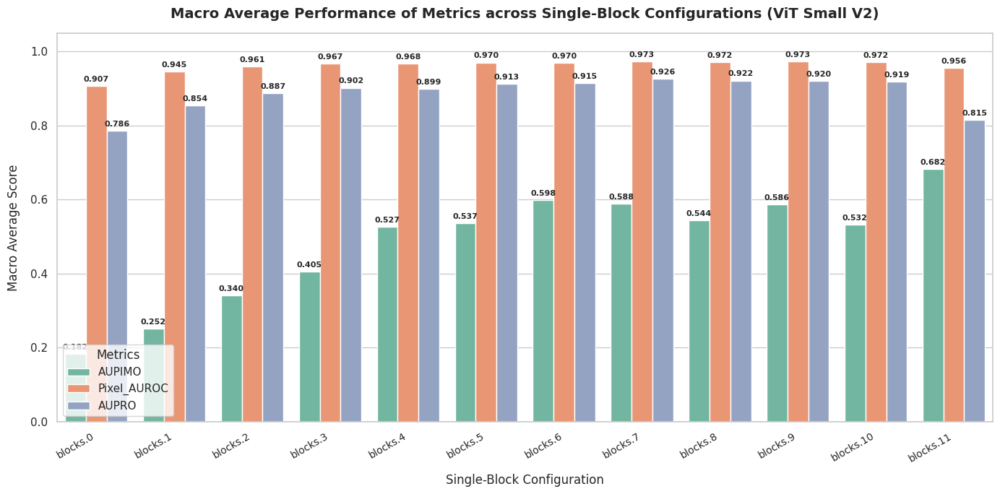

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT Small V2 dataset
excel_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_small_v2.xlsx")
if not excel_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_path}")

# 3. Load dataset
df_vit = pd.read_excel(excel_path)

# 4. Standardize categories
df_vit["Clean_Category"] = df_vit["Category"].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Filter for configurations that contain exactly ONE block (no commas)
single_block_df = df_vit[~df_vit["Layers_Used"].astype(str).str.contains(",")].copy()

# 6. Normalize layer names
def normalize_layer_names(layer_str):
    if not isinstance(layer_str, str):
        return ""
    return layer_str.strip()

single_block_df["Normalized_Layers"] = single_block_df["Layers_Used"].apply(normalize_layer_names)

# 7. Keep the latest run in case of duplicates
latest_runs_single = single_block_df.sort_values("Timestamp").groupby(["Clean_Category", "Normalized_Layers"]).last().reset_index()

# 8. Compute macro averages for single block configurations
single_block_performance = latest_runs_single.groupby("Normalized_Layers")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# Sort logically by block index (blocks.0 to blocks.11)
single_block_performance["Block_Index"] = single_block_performance["Normalized_Layers"].str.extract(r'(\d+)').astype(int)
single_block_performance = single_block_performance.sort_values("Block_Index").drop(columns=["Block_Index"])

# 9. Melt for seaborn plotting
melted_single = single_block_performance.melt(
    id_vars="Normalized_Layers",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 10. Plot the comparative metrics
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=melted_single,
    x="Normalized_Layers",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Macro Average Performance of Metrics across Single-Block Configurations (ViT Small V2)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Single-Block Configuration", fontsize=12, labelpad=10)
plt.ylabel("Macro Average Score", fontsize=12, labelpad=10)
plt.xticks(rotation=30, ha="right", fontsize=10)
plt.ylim(0.0, 1.05)
plt.legend(title="Metrics", loc="lower left")

# Annotate scores on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='semibold',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

# Grid Search ViT Base Results

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# 1. Define paths and category structures
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base_v2.xlsx")

if excel_log_path.exists():
    # 2. Read dataset
    df = pd.read_excel(excel_log_path)

    # 3. Standardize and normalize layers/categories
    df["Clean_Category"] = df["Category"].str.replace(" texture", "").str.replace(" object", "")

    def normalize_layers(layers_str):
        if not isinstance(layers_str, str):
            return ""
        parts = [p.strip() for p in layers_str.split(",")]
        parts_sorted = sorted(parts, key=lambda x: int(x.split('.')[-1]))
        return ", ".join(parts_sorted)

    df["Normalized_Layers"] = df["Layers_Used"].apply(normalize_layers)

    # 4. Group by normalized layer configuration to get macro statistics
    # We first group by class and configuration to handle any historical duplicates cleanly by keeping the latest run
    latest_runs = df.sort_values("Timestamp").groupby(["Clean_Category", "Normalized_Layers"]).last().reset_index()

    # 5. Compute macro average and standard deviation across categories for each configuration
    summary_df = latest_runs.groupby("Normalized_Layers").agg(
        AUPIMO_Mean=("AUPIMO", "mean"),
        AUPIMO_Std=("AUPIMO", "std"),
        AUPRO_Mean=("AUPRO", "mean"),
        AUPRO_Std=("AUPRO", "std"),
        Pixel_AUROC_Mean=("Pixel_AUROC", "mean"),
        Pixel_AUROC_Std=("Pixel_AUROC", "std")
    ).reset_index()

    # 6. Sort by macro average AUPIMO descending
    summary_df = summary_df.sort_values(by="AUPRO_Mean", ascending=False).reset_index(drop=True)
    summary_df.index = range(1, len(summary_df) + 1)

    # 7. Format columns for easier consumption
    summary_df.columns = [
        "Layer Configuration",
        "AUPIMO (Mean)", "AUPIMO (Std)",
        "AUPRO (Mean)", "AUPRO (Std)",
        "Pixel AUROC (Mean)", "Pixel AUROC (Std)"
    ]

    print(f"Total unique block configurations found in table: {len(summary_df)} / 78")
    pd.set_option('display.max_rows', 100)
    display(summary_df.style.highlight_max(subset=["AUPIMO (Mean)", "AUPRO (Mean)", "Pixel AUROC (Mean)"], color='#4b9184').format({
        "AUPIMO (Mean)": "{:.4f}", "AUPIMO (Std)": "{:.4f}",
        "AUPRO (Mean)": "{:.4f}", "AUPRO (Std)": "{:.4f}",
        "Pixel AUROC (Mean)": "{:.4f}", "Pixel AUROC (Std)": "{:.4f}"
    }))
else:
    print(f"Error: Excel file not found at {excel_log_path}")

Total unique block configurations found in table: 78 / 78


,Layer Configuration,AUPIMO (Mean),AUPIMO (Std),AUPRO (Mean),AUPRO (Std),Pixel AUROC (Mean),Pixel AUROC (Std)
1,"blocks.1, blocks.9",0.6324,0.2476,0.9500,0.0193,0.9827,0.0127
2,"blocks.1, blocks.8",0.6616,0.2531,0.9482,0.0222,0.9820,0.0136
3,"blocks.1, blocks.6",0.5883,0.2676,0.9480,0.0212,0.9811,0.0129
4,"blocks.1, blocks.10",0.6095,0.2504,0.9477,0.0220,0.9825,0.0127
5,"blocks.3, blocks.9",0.6242,0.3018,0.9450,0.0258,0.9815,0.0123
6,"blocks.3, blocks.8",0.6281,0.3045,0.9444,0.0297,0.9814,0.0121
7,"blocks.0, blocks.6",0.6216,0.2983,0.9443,0.0236,0.9798,0.0139
8,"blocks.6, blocks.9",0.6581,0.3277,0.9440,0.0245,0.9795,0.0139
9,"blocks.2, blocks.10",0.6125,0.3054,0.9440,0.0279,0.9815,0.0130
10,"blocks.2, blocks.9",0.6390,0.2967,0.9438,0.0294,0.9816,0.0133


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


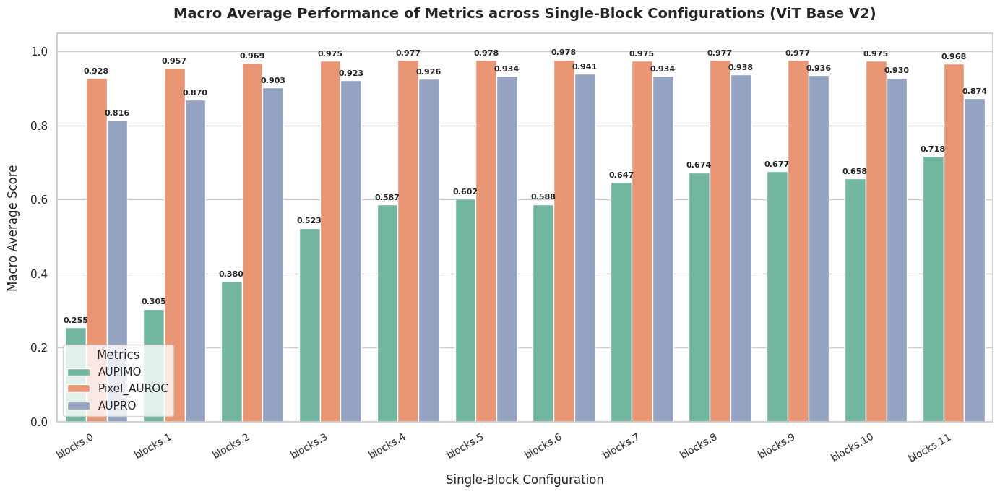

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT Small V2 dataset
excel_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_grid_search_vit_base_v2.xlsx")
if not excel_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_path}")

# 3. Load dataset
df_vit = pd.read_excel(excel_path)

# 4. Standardize categories
df_vit["Clean_Category"] = df_vit["Category"].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Filter for configurations that contain exactly ONE block (no commas)
single_block_df = df_vit[~df_vit["Layers_Used"].astype(str).str.contains(",")].copy()

# 6. Normalize layer names
def normalize_layer_names(layer_str):
    if not isinstance(layer_str, str):
        return ""
    return layer_str.strip()

single_block_df["Normalized_Layers"] = single_block_df["Layers_Used"].apply(normalize_layer_names)

# 7. Keep the latest run in case of duplicates
latest_runs_single = single_block_df.sort_values("Timestamp").groupby(["Clean_Category", "Normalized_Layers"]).last().reset_index()

# 8. Compute macro averages for single block configurations
single_block_performance = latest_runs_single.groupby("Normalized_Layers")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# Sort logically by block index (blocks.0 to blocks.11)
single_block_performance["Block_Index"] = single_block_performance["Normalized_Layers"].str.extract(r'(\d+)').astype(int)
single_block_performance = single_block_performance.sort_values("Block_Index").drop(columns=["Block_Index"])

# 9. Melt for seaborn plotting
melted_single = single_block_performance.melt(
    id_vars="Normalized_Layers",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 10. Plot the comparative metrics
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=melted_single,
    x="Normalized_Layers",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Macro Average Performance of Metrics across Single-Block Configurations (ViT Base V2)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Single-Block Configuration", fontsize=12, labelpad=10)
plt.ylabel("Macro Average Score", fontsize=12, labelpad=10)
plt.xticks(rotation=30, ha="right", fontsize=10)
plt.ylim(0.0, 1.05)
plt.legend(title="Metrics", loc="lower left")

# Annotate scores on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='semibold',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

# Final Grid Search Small

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, PRO, AUPRO, AUPIMO

torch.set_float32_matmul_precision('high')

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_small.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_small_patch16_dinov3"
CORESET_RATIO = [0.01, 0.03, 0.05, 0.07]
KNN_NEIGHBORS = 9
pool_size = 1
layer_experiments = [["blocks.11"], ["blocks.6", "blocks.11"], ["blocks.1", "blocks.6"]]

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    for blocks in layer_experiments:
      gc.collect()
      torch.cuda.empty_cache()

      metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
      ]

      evaluator = Evaluator(test_metrics=metrics)

      # 3. DataModule Configuration
      datamodule = MVTecAD(
          root=drive_dataset_root,
          category=category,
          train_batch_size=32,
          eval_batch_size=32,
          num_workers=4,
      )

      # 4. PatchCore Model Configuration
      model = Patchcore(
          backbone=BACKBONE,
          layers=blocks,
          coreset_sampling_ratio=coreset_ratio,
          num_neighbors=KNN_NEIGHBORS,
          evaluator=evaluator,
      )

      # Apply Feature Pooler override
      if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
          padding = pool_size // 2
          model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
          print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
      else:
          print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

      # 5. Engine Setup
      engine = Engine(
          default_root_dir="./results",
          accelerator="gpu",
          devices=1,
          enable_progress_bar=False,
      )

      start_time = time.perf_counter()

      # 6. Fit and Test
      print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
      engine.fit(datamodule=datamodule, model=model)

      training_duration = round(time.perf_counter() - start_time, 2)
      print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

      print("Running test evaluation...")
      test_results_raw = engine.test(datamodule=datamodule, model=model)

      test_results = test_results_raw[0] if test_results_raw else {}

      # 7. Extract Metric Scores
      image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
      pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
      aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
      aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))

      new_record = {
          "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
          "Training_Time_Sec": training_duration,
          "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
          "Backbone": BACKBONE,
          "Layers_Used": ", ".join(blocks),
          "Pool_Size": pool_size,
          "Coreset_Ratio": coreset_ratio,
          "KNN": KNN_NEIGHBORS,
          "Image_AUROC": round(float(image_auroc), 4),
          "Pixel_AUROC": round(float(pixel_auroc), 4),
          "AUPRO": round(float(aupro), 4),
          "AUPIMO": round(float(aupimo), 4),
      }

      new_df = pd.DataFrame([new_record])

      # 8. Append to Persistent Excel Spreadsheet
      if excel_log_path.exists():
          existing_df = pd.read_excel(excel_log_path)
          updated_df = pd.concat([existing_df, new_df], ignore_index=True)
      else:
          updated_df = new_df

      updated_df.to_excel(excel_log_path, index=False)
      print(f"\nExperiment successfully logged to: {excel_log_path}")

      # Display current logged history
      print("\n========== EXPERIMENT LOG HISTORY ==========")
      print(updated_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'evaluator' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['evaluator'])`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

Training completed in: 29.63s (0.49 min)
Running test evaluation...


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.3305708411717076     │
│           AUPRO           │     0.919564425945282     │
│        image_AUROC        │    0.9885965585708618     │
│        pixel_AUROC        │     0.963607132434845     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_small.xlsx

========== EXPERIMENT LOG HISTORY ==========
          Timestamp  Training_Time_Sec          Category                 Backbone         Layers_Used  Pool_Size  Coreset_Ratio  KNN  Image_AUROC  Pixel_AUROC  AUPRO  AUPIMO
2026-10-05 09:38:56              34.61     bottle object vit_small_patch16_dinov3           blocks.11          1           0.01    9       0.9976       0.9791 0.8488  0.8979
2026-10-05 09:39:38              14.36     bottle object vit_small_patch16_dinov3 blocks.6, blocks.11          1           0.01    9       1.0000       0.9896 0.9509  0.8483
2026-10-05 09:40:21              14.85     bottle object vit_small_patch16_dinov3  blocks.1, blocks.6          1           0.01    9       1.0000       0.9907 0.9636  0.8347
2026-10-05 09:41:02              15.18     bottle object vit_small_patch16_dinov3           blocks.11          1           0.03    9    

# Data Viz

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


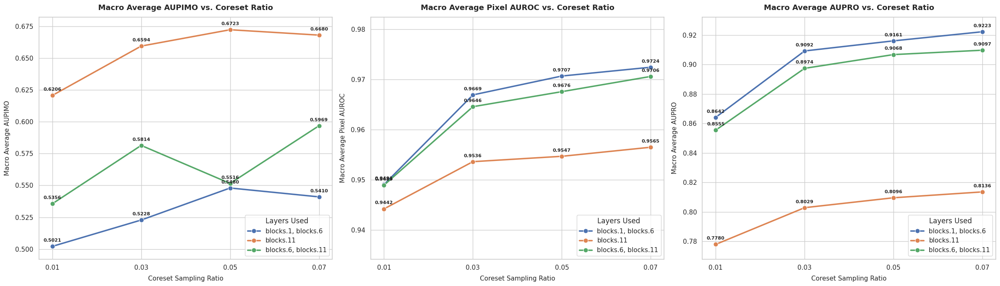

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the spreadsheet
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_small.xlsx")

if not excel_log_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path}")

# 3. Load dataset
df = pd.read_excel(excel_log_path)

# 4. Standardize and clean category names
df["Clean_Category"] = df["Category"].str.replace(" texture", "").str.replace(" object", "")

# 5. Group by Coreset Ratio and Layers Used to compute macro statistics
latest_runs = df.sort_values("Timestamp").groupby(["Clean_Category", "Coreset_Ratio", "Layers_Used"]).last().reset_index()

# Calculate macro averages across classes for each metric
macro_summary = latest_runs.groupby(["Coreset_Ratio", "Layers_Used"])[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# 6. Set up visualization theme
sns.set_theme(style="whitegrid")
metrics_to_plot = [
    ("AUPIMO", "Macro Average AUPIMO"),
    ("Pixel_AUROC", "Macro Average Pixel AUROC"),
    ("AUPRO", "Macro Average AUPRO")
]

# Create 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharex=True)

for idx, (col_name, label) in enumerate(metrics_to_plot):
    ax = axes[idx]
    sns.lineplot(
        data=macro_summary,
        x="Coreset_Ratio",
        y=col_name,
        hue="Layers_Used",
        marker="o",
        linewidth=2.5,
        markersize=8,
        ax=ax
    )

    ax.set_title(f"{label} vs. Coreset Ratio", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Coreset Sampling Ratio", fontsize=11, labelpad=8)
    ax.set_ylabel(label, fontsize=11, labelpad=8)
    ax.set_xticks(sorted(macro_summary["Coreset_Ratio"].unique()))

    min_val = macro_summary[col_name].min()
    max_val = macro_summary[col_name].max()
    ax.set_ylim(min_val - 0.01, min(max_val + 0.01, 1.0))
    ax.legend(title="Layers Used", loc="lower right")

    # Annotate the values on the line points
    for layers in macro_summary["Layers_Used"].unique():
        subset_df = macro_summary[macro_summary["Layers_Used"] == layers]
        for x, y in zip(subset_df["Coreset_Ratio"], subset_df[col_name]):
            ax.annotate(
                f"{y:.4f}",
                (x, y),
                textcoords="offset points",
                xytext=(0, 8),
                ha='center',
                fontsize=8,
                fontweight='semibold'
            )

plt.tight_layout()
plt.show()

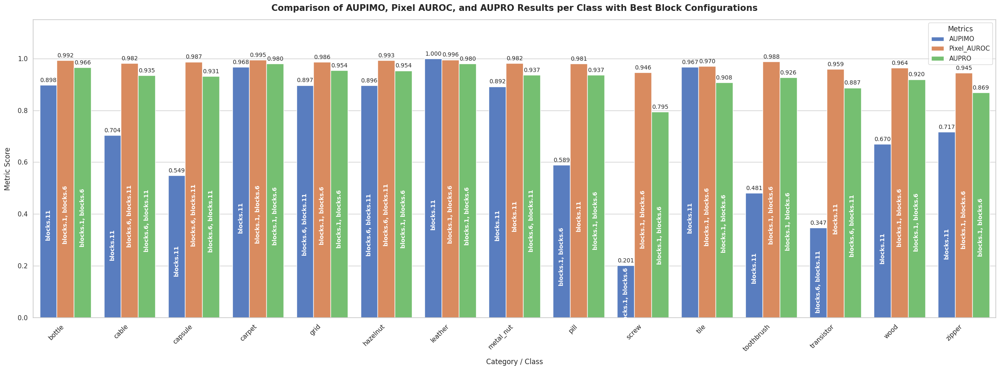

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Standardize categories
latest_runs["Clean_Category"] = latest_runs["Category"].str.replace(" texture", "").str.replace(" object", "")

# 2. Extract best record and the corresponding configuration for each metric per class
# We will build a helper dictionary mapping (Class, Metric) -> (Best_Score, Best_Block_Name)
best_configs = {}
for metric in ["AUPIMO", "Pixel_AUROC", "AUPRO"]:
    # Find index of maximum value for this metric within each category
    idx_max = latest_runs.groupby("Clean_Category")[metric].idxmax()
    best_rows = latest_runs.loc[idx_max]
    for _, row in best_rows.iterrows():
        best_configs[(row["Clean_Category"], metric)] = {
            "score": row[metric],
            "block": row["Layers_Used"]
        }

# 3. Create the melted dataframe for plotting
class_summary = latest_runs.groupby("Clean_Category")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].max().reset_index()
melted_class = class_summary.melt(
    id_vars="Clean_Category",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 4. Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(24, 9))

ax = sns.barplot(
    data=melted_class,
    x="Clean_Category",
    y="Score",
    hue="Metric",
    palette="muted"
)

plt.title("Comparison of AUPIMO, Pixel AUROC, and AUPRO Results per Class with Best Block Configurations", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Category / Class", fontsize=12, labelpad=10)
plt.ylabel("Metric Score", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.ylim(0.0, 1.15)
plt.legend(title="Metrics", loc="upper right")

# Ensure we match matplotlib's generated bars to our helper records to plot exact values and names
# Seaborn barplots draw bars in order of hue (Metric) then x (Clean_Category)
categories = sorted(melted_class["Clean_Category"].unique())
metrics = ["AUPIMO", "Pixel_AUROC", "AUPRO"]

# Get all drawn patches representing the bars
patches = ax.patches
num_categories = len(categories)

for i, p in enumerate(patches):
    height = p.get_height()
    if height > 0:
        # Determine which metric and category this bar corresponds to
        metric_idx = i // num_categories
        category_idx = i % num_categories

        metric_name = metrics[metric_idx]
        category_name = categories[category_idx]

        best_info = best_configs.get((category_name, metric_name), {"score": height, "block": "N/A"})
        block_label = best_info["block"]

        # Annotate score value above the bar
        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=10,
            xytext=(0, 3),
            textcoords='offset points',
            rotation=0
        )

        # Annotate best block name vertically inside the bar
        # Placed at 40% height of the bar to be visible
        ax.annotate(
            block_label,
            (p.get_x() + p.get_width() / 2., height * 0.40),
            ha='center',
            va='center',
            color='white',
            fontsize=10,
            fontweight='bold',
            rotation=90
        )

plt.tight_layout()
plt.show()

Mounted at /content/drive


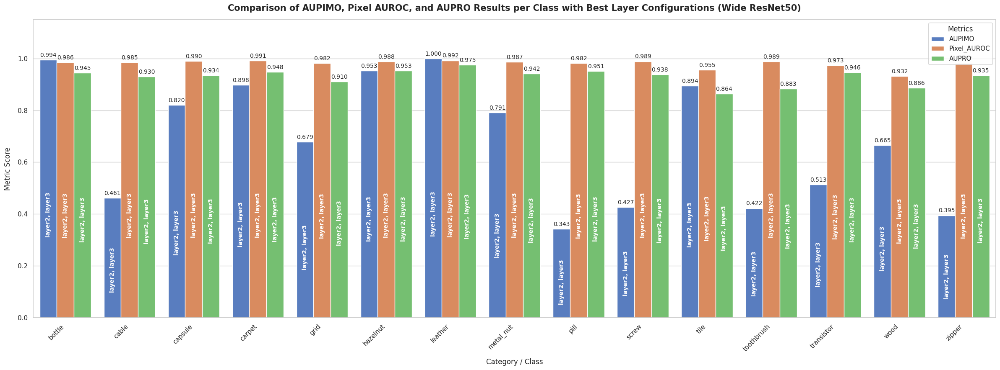

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=False)

# 2. Path to the Wide ResNet50 dataset
excel_log_path_wrn = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_wide_resnet50.xlsx")
if not excel_log_path_wrn.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path_wrn}")

# 3. Load dataset
df_wrn = pd.read_excel(excel_log_path_wrn)

# 4. Standardize and clean category names
# If 'Category' column is present, clean it. Otherwise use 'Class' or 'Clean_Category'.
category_col = "Category" if "Category" in df_wrn.columns else "Class"
df_wrn["Clean_Category"] = df_wrn[category_col].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs based on Category, Coreset_Ratio, and Layers_Used
# Adjust grouping columns based on available columns
group_cols = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df_wrn.columns else ["Clean_Category", "Layers_Used"]
latest_runs_wrn = df_wrn.sort_values("Timestamp").groupby(group_cols).last().reset_index() if "Timestamp" in df_wrn.columns else df_wrn

# 6. Extract best record and the corresponding configuration for each metric per class
best_configs_wrn = {}
for metric in ["AUPIMO", "Pixel_AUROC", "AUPRO"]:
    if metric in latest_runs_wrn.columns:
        idx_max = latest_runs_wrn.groupby("Clean_Category")[metric].idxmax()
        best_rows = latest_runs_wrn.loc[idx_max]
        for _, row in best_rows.iterrows():
            best_configs_wrn[(row["Clean_Category"], metric)] = {
                "score": row[metric],
                "block": row["Layers_Used"]
            }

# 7. Create the melted dataframe for plotting
class_summary_wrn = latest_runs_wrn.groupby("Clean_Category")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].max().reset_index()
melted_class_wrn = class_summary_wrn.melt(
    id_vars="Clean_Category",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 8. Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(24, 9))

ax = sns.barplot(
    data=melted_class_wrn,
    x="Clean_Category",
    y="Score",
    hue="Metric",
    palette="muted"
)

plt.title("Comparison of AUPIMO, Pixel AUROC, and AUPRO Results per Class with Best Layer Configurations (Wide ResNet50)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Category / Class", fontsize=12, labelpad=10)
plt.ylabel("Metric Score", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.ylim(0.0, 1.15)
plt.legend(title="Metrics", loc="upper right")

categories_wrn = sorted(melted_class_wrn["Clean_Category"].unique())
metrics_wrn = ["AUPIMO", "Pixel_AUROC", "AUPRO"]
patches_wrn = ax.patches
num_categories_wrn = len(categories_wrn)

for i, p in enumerate(patches_wrn):
    height = p.get_height()
    if height > 0:
        metric_idx = i // num_categories_wrn
        category_idx = i % num_categories_wrn

        metric_name = metrics_wrn[metric_idx]
        category_name = categories_wrn[category_idx]

        best_info = best_configs_wrn.get((category_name, metric_name), {"score": height, "block": "N/A"})
        block_label = best_info["block"]

        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=10,
            xytext=(0, 3),
            textcoords='offset points',
            rotation=0
        )

        ax.annotate(
            str(block_label),
            (p.get_x() + p.get_width() / 2., height * 0.40),
            ha='center',
            va='center',
            color='white',
            fontsize=10,
            fontweight='bold',
            rotation=90
        )

plt.tight_layout()
plt.show()

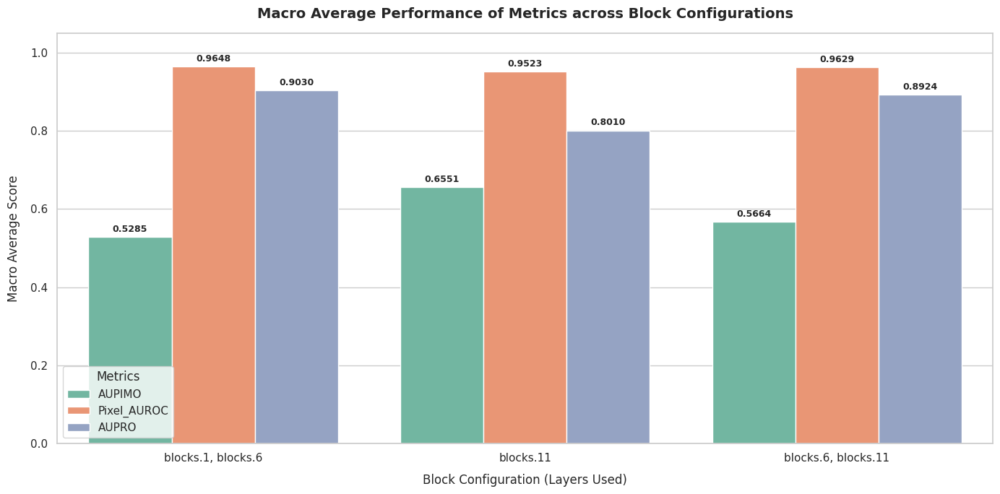

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate macro average for each metric across the block configurations
block_performance = latest_runs.groupby("Layers_Used")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# 2. Melt the dataframe to long-format for comparative plotting
melted_blocks = block_performance.melt(
    id_vars="Layers_Used",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 3. Setup the visual representation
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=melted_blocks,
    x="Layers_Used",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Macro Average Performance of Metrics across Block Configurations", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Block Configuration (Layers Used)", fontsize=12, labelpad=10)
plt.ylabel("Macro Average Score", fontsize=12, labelpad=10)
plt.ylim(0.0, 1.05)
plt.legend(title="Metrics", loc="lower left")

# Annotate the score values on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.4f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='semibold',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

Mounted at /content/drive


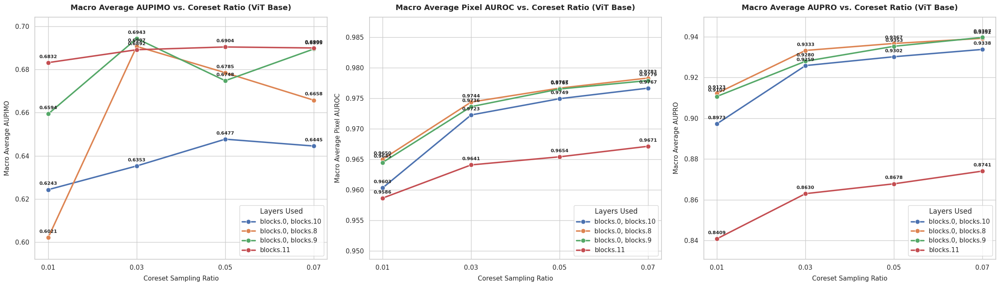

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the Vit-Base spreadsheet
excel_log_path_base = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_base.xlsx")

if not excel_log_path_base.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path_base}")

# 3. Load dataset
df_base = pd.read_excel(excel_log_path_base)

# 4. Standardize and clean category names
df_base["Clean_Category"] = df_base["Category"].str.replace(" texture", "").str.replace(" object", "")

# 5. Group by Coreset Ratio and Layers Used to compute macro statistics
latest_runs_base = df_base.sort_values("Timestamp").groupby(["Clean_Category", "Coreset_Ratio", "Layers_Used"]).last().reset_index()

# Calculate macro averages across classes for each metric
macro_summary_base = latest_runs_base.groupby(["Coreset_Ratio", "Layers_Used"])[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# 6. Set up visualization theme
sns.set_theme(style="whitegrid")
metrics_to_plot = [
    ("AUPIMO", "Macro Average AUPIMO"),
    ("Pixel_AUROC", "Macro Average Pixel AUROC"),
    ("AUPRO", "Macro Average AUPRO")
]

# Create 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharex=True)

for idx, (col_name, label) in enumerate(metrics_to_plot):
    ax = axes[idx]
    sns.lineplot(
        data=macro_summary_base,
        x="Coreset_Ratio",
        y=col_name,
        hue="Layers_Used",
        marker="o",
        linewidth=2.5,
        markersize=8,
        ax=ax
    )

    ax.set_title(f"{label} vs. Coreset Ratio (ViT Base)", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Coreset Sampling Ratio", fontsize=11, labelpad=8)
    ax.set_ylabel(label, fontsize=11, labelpad=8)
    ax.set_xticks(sorted(macro_summary_base["Coreset_Ratio"].unique()))

    min_val = macro_summary_base[col_name].min()
    max_val = macro_summary_base[col_name].max()
    ax.set_ylim(min_val - 0.01, min(max_val + 0.01, 1.0))
    ax.legend(title="Layers Used", loc="lower right")

    # Annotate the values on the line points
    for layers in macro_summary_base["Layers_Used"].unique():
        subset_df = macro_summary_base[macro_summary_base["Layers_Used"] == layers]
        for x, y in zip(subset_df["Coreset_Ratio"], subset_df[col_name]):
            ax.annotate(
                f"{y:.4f}",
                (x, y),
                textcoords="offset points",
                xytext=(0, 8),
                ha='center',
                fontsize=8,
                fontweight='semibold'
            )

plt.tight_layout()
plt.show()

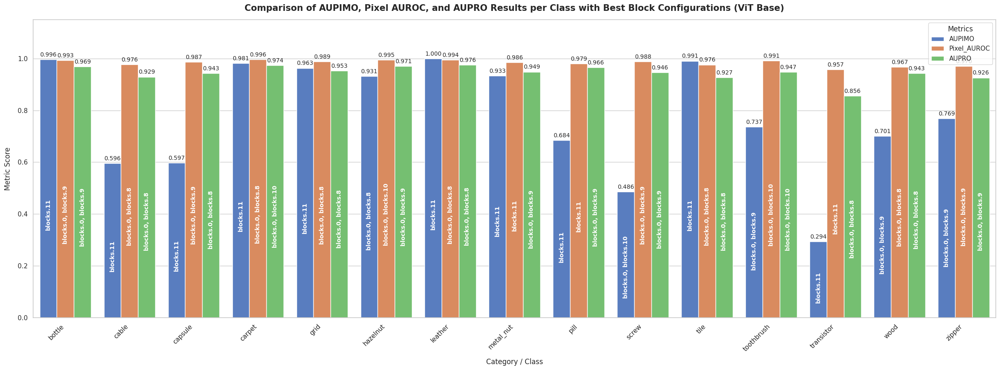

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Standardize categories
latest_runs_base["Clean_Category"] = latest_runs_base["Category"].str.replace(" texture", "").str.replace(" object", "")

# 2. Extract best record and the corresponding configuration for each metric per class
best_configs_base = {}
for metric in ["AUPIMO", "Pixel_AUROC", "AUPRO"]:
    idx_max = latest_runs_base.groupby("Clean_Category")[metric].idxmax()
    best_rows = latest_runs_base.loc[idx_max]
    for _, row in best_rows.iterrows():
        best_configs_base[(row["Clean_Category"], metric)] = {
            "score": row[metric],
            "block": row["Layers_Used"]
        }

# 3. Create the melted dataframe for plotting
class_summary_base = latest_runs_base.groupby("Clean_Category")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].max().reset_index()
melted_class_base = class_summary_base.melt(
    id_vars="Clean_Category",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 4. Plotting
sns.set_theme(style="whitegrid")
plt.figure(figsize=(24, 9))

ax = sns.barplot(
    data=melted_class_base,
    x="Clean_Category",
    y="Score",
    hue="Metric",
    palette="muted"
)

plt.title("Comparison of AUPIMO, Pixel AUROC, and AUPRO Results per Class with Best Block Configurations (ViT Base)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Category / Class", fontsize=12, labelpad=10)
plt.ylabel("Metric Score", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.ylim(0.0, 1.15)
plt.legend(title="Metrics", loc="upper right")

categories_base = sorted(melted_class_base["Clean_Category"].unique())
metrics_base = ["AUPIMO", "Pixel_AUROC", "AUPRO"]
patches_base = ax.patches
num_categories_base = len(categories_base)

for i, p in enumerate(patches_base):
    height = p.get_height()
    if height > 0:
        metric_idx = i // num_categories_base
        category_idx = i % num_categories_base

        metric_name = metrics_base[metric_idx]
        category_name = categories_base[category_idx]

        best_info = best_configs_base.get((category_name, metric_name), {"score": height, "block": "N/A"})
        block_label = best_info["block"]

        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=10,
            xytext=(0, 3),
            textcoords='offset points',
            rotation=0
        )

        ax.annotate(
            block_label,
            (p.get_x() + p.get_width() / 2., height * 0.40),
            ha='center',
            va='center',
            color='white',
            fontsize=10,
            fontweight='bold',
            rotation=90
        )

plt.tight_layout()
plt.show()

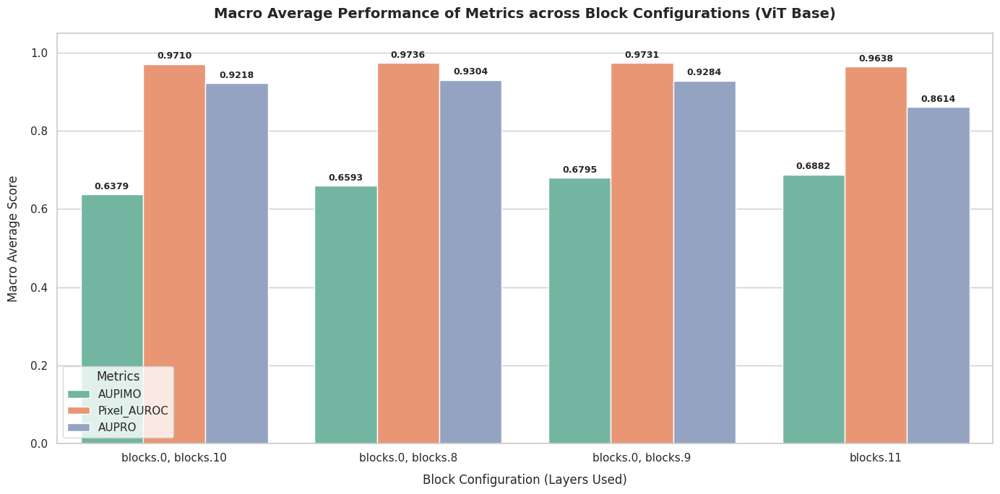

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate macro average for each metric across the block configurations
block_performance_base = latest_runs_base.groupby("Layers_Used")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()

# 2. Melt the dataframe to long-format for comparative plotting
melted_blocks_base = block_performance_base.melt(
    id_vars="Layers_Used",
    value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"],
    var_name="Metric",
    value_name="Score"
)

# 3. Setup the visual representation
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=melted_blocks_base,
    x="Layers_Used",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Macro Average Performance of Metrics across Block Configurations (ViT Base)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Block Configuration (Layers Used)", fontsize=12, labelpad=10)
plt.ylabel("Macro Average Score", fontsize=12, labelpad=10)
plt.ylim(0.0, 1.05)
plt.legend(title="Metrics", loc="lower left")

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.4f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='semibold',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


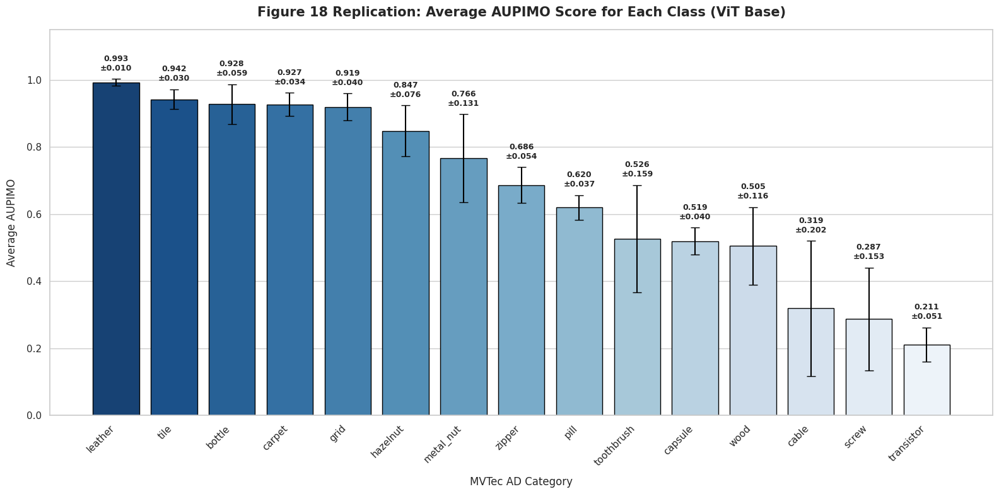

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT-Base dataset
excel_log_path_base = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_base.xlsx")
if not excel_log_path_base.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path_base}")

# 3. Load dataset
df_base = pd.read_excel(excel_log_path_base)

# 4. Standardize and clean category names
df_base["Clean_Category"] = df_base["Category"].str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
latest_runs_base = df_base.sort_values("Timestamp").groupby(["Clean_Category", "Coreset_Ratio", "Layers_Used"]).last().reset_index()

# 6. Calculate Average AUPIMO and Std Dev for each category across all configurations
class_aupimo_stats = latest_runs_base.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
class_aupimo_stats = class_aupimo_stats.sort_values(by="Mean_AUPIMO", ascending=False)

# 7. Create Visualization mimicking Figure 18 style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 8))

# Create bar plot and capture the bar positions
ax = sns.barplot(
    data=class_aupimo_stats,
    x="Clean_Category",
    y="Mean_AUPIMO",
    hue="Clean_Category",
    palette="Blues_r",
    edgecolor="black",
    legend=False
)

# Add the error bars manually using errorbar to avoid shape mismatch issues
x_coords = range(len(class_aupimo_stats))
plt.errorbar(
    x=x_coords,
    y=class_aupimo_stats["Mean_AUPIMO"],
    yerr=class_aupimo_stats["Std_AUPIMO"],
    fmt='none',
    color='black',
    capsize=5,
    elinewidth=1.5
)

plt.title("Figure 18 Replication: Average AUPIMO Score for Each Class (ViT Base)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("MVTec AD Category", fontsize=12, labelpad=10)
plt.ylabel("Average AUPIMO", fontsize=12, labelpad=10)
plt.xticks(ticks=x_coords, labels=class_aupimo_stats["Clean_Category"], rotation=45, ha="right", fontsize=11)
plt.ylim(0.0, 1.15)

# Annotate the exact average score values on top of each bar
for idx, p in enumerate(ax.patches):
    height = p.get_height()
    mean_val = class_aupimo_stats.iloc[idx]["Mean_AUPIMO"]
    std_val = class_aupimo_stats.iloc[idx]["Std_AUPIMO"]
    ax.annotate(
        f"{mean_val:.3f}\n±{std_val:.3f}",
        (p.get_x() + p.get_width() / 2., max(height, mean_val + std_val) + 0.02),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


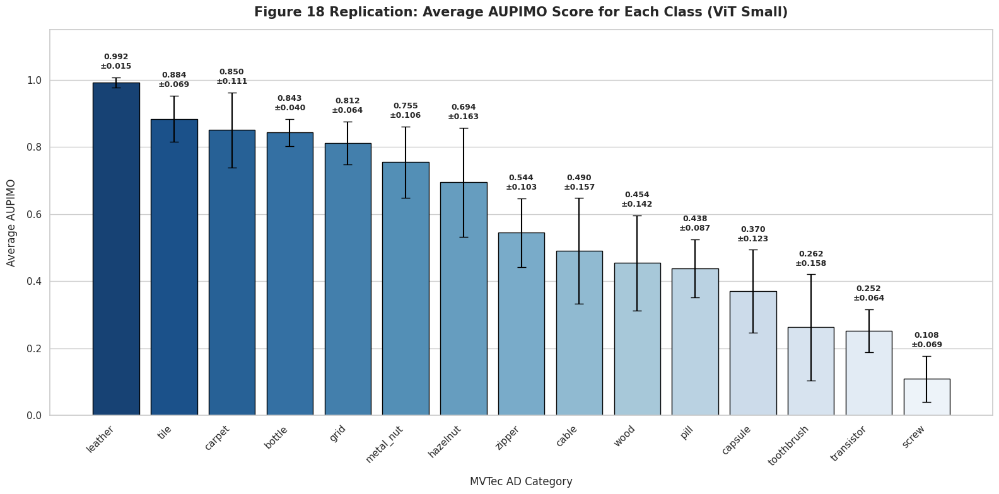

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT-Small dataset
excel_log_path_small = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_final_gridsearch_vit_small.xlsx")
if not excel_log_path_small.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path_small}")

# 3. Load dataset
df_small = pd.read_excel(excel_log_path_small)

# 4. Standardize and clean category names
df_small["Clean_Category"] = df_small["Category"].str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
latest_runs_small = df_small.sort_values("Timestamp").groupby(["Clean_Category", "Coreset_Ratio", "Layers_Used"]).last().reset_index()

# 6. Calculate Average AUPIMO and Std Dev for each category across all configurations
class_aupimo_stats_small = latest_runs_small.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
class_aupimo_stats_small = class_aupimo_stats_small.sort_values(by="Mean_AUPIMO", ascending=False)

# 7. Create Visualization mimicking Figure 18 style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 8))

# Create bar plot and capture the bar positions
ax = sns.barplot(
    data=class_aupimo_stats_small,
    x="Clean_Category",
    y="Mean_AUPIMO",
    hue="Clean_Category",
    palette="Blues_r",
    edgecolor="black",
    legend=False
)

# Add the error bars manually using errorbar to avoid shape mismatch issues
x_coords = range(len(class_aupimo_stats_small))
plt.errorbar(
    x=x_coords,
    y=class_aupimo_stats_small["Mean_AUPIMO"],
    yerr=class_aupimo_stats_small["Std_AUPIMO"],
    fmt='none',
    color='black',
    capsize=5,
    elinewidth=1.5
)

plt.title("Figure 18 Replication: Average AUPIMO Score for Each Class (ViT Small)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("MVTec AD Category", fontsize=12, labelpad=10)
plt.ylabel("Average AUPIMO", fontsize=12, labelpad=10)
plt.xticks(ticks=x_coords, labels=class_aupimo_stats_small["Clean_Category"], rotation=45, ha="right", fontsize=11)
plt.ylim(0.0, 1.15)

# Annotate the exact average score values on top of each bar
for idx, p in enumerate(ax.patches):
    height = p.get_height()
    mean_val = class_aupimo_stats_small.iloc[idx]["Mean_AUPIMO"]
    std_val = class_aupimo_stats_small.iloc[idx]["Std_AUPIMO"]
    ax.annotate(
        f"{mean_val:.3f}\n±{std_val:.3f}",
        (p.get_x() + p.get_width() / 2., max(height, mean_val + std_val) + 0.02),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

# Grid Search ViT Base (Seed)

In [ ]:
import sys
import gc
import datetime
import time
import random
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np
import torch
from lightning.pytorch import seed_everything

# Restore missing imports to resolve NameError
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, AUPRO, AUPIMO, Evaluator

torch.set_float32_matmul_precision('high')

# Configure seed value
RUN_SEED = 3110

def set_reproducible_seed(seed=3110):
    # 1. PyTorch Lightning utility sets seeds for Python random, numpy, and pytorch (both CPU and CUDA)
    seed_everything(seed, workers=True)

    # 2. Additional PyTorch reproducibility flags
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Global seed set to: {seed}")

# Call the helper at the very beginning of your execution
set_reproducible_seed(RUN_SEED)

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]
KNN_NEIGHBORS = 9
pool_size = 1
layer_experiments = [["blocks.6"], ["blocks.9"], ["blocks.0", "blocks.9"], ["blocks.1", "blocks.9"]]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    for blocks in layer_experiments:
      gc.collect()
      torch.cuda.empty_cache()

      metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
      ]

      evaluator = Evaluator(test_metrics=metrics)

      # 3. DataModule Configuration
      datamodule = MVTecAD(
          root=drive_dataset_root,
          category=category,
          train_batch_size=32,
          eval_batch_size=32,
          num_workers=4,
      )

      # 4. PatchCore Model Configuration
      model = Patchcore(
          backbone=BACKBONE,
          layers=blocks,
          coreset_sampling_ratio=coreset_ratio,
          num_neighbors=KNN_NEIGHBORS,
          evaluator=evaluator,
      )

      # Apply Feature Pooler override
      if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
          padding = pool_size // 2
          model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
          print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
      else:
          print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

      # 5. Engine Setup
      engine = Engine(
          default_root_dir="./results",
          accelerator="gpu",
          devices=1,
          enable_progress_bar=False,
      )

      start_time = time.perf_counter()

      # 6. Fit and Test
      print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
      engine.fit(datamodule=datamodule, model=model)

      training_duration = round(time.perf_counter() - start_time, 2)
      print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

      print("Running test evaluation...")
      test_results_raw = engine.test(datamodule=datamodule, model=model)

      test_results = test_results_raw[0] if test_results_raw else {}

      # 7. Extract Metric Scores
      image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
      pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
      aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
      aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))
      memory_bank_size_mb = estimate_memory_bank_size(model)

      new_record = {
          "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
          "Training_Time_Sec": training_duration,
          "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
          "Backbone": BACKBONE,
          "Layers_Used": ", ".join(blocks),
          "Pool_Size": pool_size,
          "Coreset_Ratio": coreset_ratio,
          "KNN": KNN_NEIGHBORS,
          "Seed": RUN_SEED,
          "Image_AUROC": round(float(image_auroc), 4),
          "Pixel_AUROC": round(float(pixel_auroc), 4),
          "AUPRO": round(float(aupro), 4),
          "AUPIMO": round(float(aupimo), 4),
          "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
      }

      new_df = pd.DataFrame([new_record])

      # 8. Append to Persistent Excel Spreadsheet
      if excel_log_path.exists():
          existing_df = pd.read_excel(excel_log_path)
          updated_df = pd.concat([existing_df, new_df], ignore_index=True)
      else:
          updated_df = new_df

      updated_df.to_excel(excel_log_path, index=False)
      print(f"\nExperiment successfully logged to: {excel_log_path}")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
INFO: Seed set to 3110
INFO:lightning.fabric.utilities.seed:Seed set to 3110


Global seed set to: 3110
Mounted at /content/drive


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


...

Trainable params: 85.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 85.6 M                                                                                               
Total estimated model params size (MB): 342.565                                                                    
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 253 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 1535/1535 [00:00<00:00, 6598.64it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training completed in: 7.15s (0.12 min)
Running test evaluation...


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │     0.676412398938566     │
│           AUPRO           │    0.9481194019317627     │
│        image_AUROC        │    0.9944444298744202     │
│        pixel_AUROC        │    0.9908528327941895     │
└───────────────────────────┴───────────────────────────┘

OSError: [Errno 28] No space left on device